# Phase 6 · Evaluation and conclusions

**Project 1 · FAA · breast_cancer (classification)**

**What this notebook does:** it compares the five learners with the outer validation from Phase 5, measures calibration, uses the **final test set only once**, analyses the errors and answers the hypotheses from Phase 1.

**Requires** `utils_python.py` and `models_python.py` in the same folder and the tables in `results/` from Phase 5.

### Cell 1: import the libraries

We import the libraries. New ones: `binomtest` (for McNemar and the Wilson interval) and `calibration_curve` (reliability curve).

In [1]:
import os  # os: configure the environment
import time  # time: measure times
import warnings  # warnings: silence repetitive warnings
import numpy as np  # numpy: numerical computing with arrays
import polars as pl  # polars: result tables
import matplotlib.pyplot as plt  # matplotlib: draws the plots
from scipy.stats import binomtest  # binomial test (exact McNemar and Wilson interval)
from sklearn.base import clone  # clone: copies a model without training
from sklearn.calibration import calibration_curve  # reliability curve
from sklearn.linear_model import LogisticRegression  # logistic regression (comparison with the evolutionary learner)
from sklearn.metrics import confusion_matrix, make_scorer, matthews_corrcoef  # metrics
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict  # tuning with cross-validation
from utils_python import load_data, make_folds, compute_metrics, best_threshold, corrected_ttest, summarize  # functions from Phase 3
from models_python import learners, build, EvolutionaryClassifier  # learners from Phase 4
os.environ["PYTHONWARNINGS"] = "ignore"  # no warnings in the parallel processes
warnings.filterwarnings("ignore")  # no repetitive warnings

### Cell 2: load the data and the Phase 5 results

We load the data and the two tables left by Phase 5. **The test set has not been used yet.**

In [2]:
X_train, X_test, y_train, y_test, columns, path = load_data()  # same 455/114 split
folds = make_folds(X_train, y_train)  # the 25 outer folds
results_dir = path.parent.parent / "results"  # where Phase 5 saved its tables
figures_dir = path.parent.parent / "figures" / "06_evaluation"  # plots of this phase
figures_dir.mkdir(parents=True, exist_ok=True)  # create it if it does not exist
results = pl.read_csv(results_dir / "outer_folds.csv")  # metrics per learner and outer fold
scores = pl.read_csv(results_dir / "outer_scores.csv")  # probability of each validation tumour
keys = list(learners)  # ["tree", "mlp", "evolutionary", "bayes", "svm"]
names = {"tree": "Tree", "mlp": "MLP", "evolutionary": "Evolutionary", "bayes": "Naive Bayes", "svm": "SVM"}  # names for the tables
n_train, n_val = len(folds[0][0]), len(folds[0][1])  # 364 and 91 (for the corrected t-test)
print("Result rows:", results.height, "(5 learners x 25 folds)")  # check
print("The test set (", len(y_test), "rows) has not been used yet")  # reminder

Result rows: 125 (5 learners x 25 folds)
The test set ( 114 rows) has not been used yet


### Cell 3: results table in the outer cross-validation (threshold 0.5)

## 1) Comparison in the outer cross-validation

Results of the 25 outer folds with threshold 0.5 (mean ± standard deviation across folds).

In [3]:
print(f"{'Learner':12s} {'MCC':>14s} {'Recall':>14s} {'AUC':>14s} {'Brier':>14s} {'Log-loss':>14s}")  # header
for key in keys:  # one line per learner
    sub = results.filter(pl.col("learner") == key).sort("fold")  # its 25 folds
    cells = []  # the formatted metrics go here
    for metric in ["mcc", "recall", "auc", "brier", "logloss"]:  # the metrics of the table
        mean, std, _ = summarize(sub[f"t05_{metric}"].to_numpy())  # mean and standard deviation across folds
        cells.append(f"{mean:.3f} ± {std:.3f}")  # text "mean ± standard deviation"
    print(f"{names[key]:12s} " + " ".join(f"{c:>14s}" for c in cells))  # one table line
print("Baseline (always benign / always malignant): MCC 0 | recall 0 / 1 | AUC 0.5 | cost 1.868 / 0.626")  # from Phase 3

Learner                 MCC         Recall            AUC          Brier       Log-loss
Tree          0.841 ± 0.064  0.886 ± 0.061  0.935 ± 0.031  0.067 ± 0.026  0.582 ± 0.300
MLP           0.945 ± 0.033  0.948 ± 0.034  0.994 ± 0.006  0.021 ± 0.009  0.102 ± 0.077
Evolutionary  0.926 ± 0.036  0.938 ± 0.033  0.991 ± 0.008  0.030 ± 0.015  0.196 ± 0.110
Naive Bayes   0.889 ± 0.050  0.913 ± 0.050  0.988 ± 0.008  0.050 ± 0.022  0.388 ± 0.193
SVM           0.943 ± 0.029  0.948 ± 0.030  0.994 ± 0.006  0.021 ± 0.010  0.082 ± 0.035
Baseline (always benign / always malignant): MCC 0 | recall 0 / 1 | AUC 0.5 | cost 1.868 / 0.626


**What we see:** MLP (0.945) and SVM (0.943) lead, the evolutionary learner (0.926) comes just behind, Naive Bayes (0.889) drops a step and the tree (0.841) is the worst and the most variable (±0.064). All beat the baseline (MCC 0). The dispersion across folds (±0.03) is larger than the distance between the top three.

### Cell 4: dispersion across folds

The same information as a plot: each point is a fold. The **dispersion** matters as much as the mean.

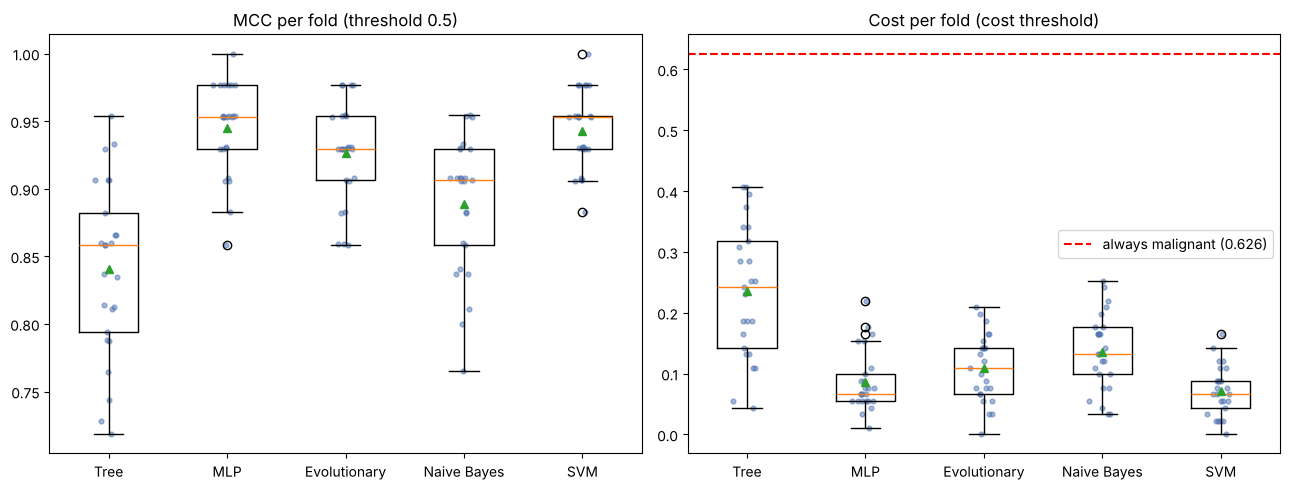

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))  # two plots side by side
for ax, (prefix, metric, title) in zip(axes, [("t05", "mcc", "MCC per fold (threshold 0.5)"), ("tcost", "cost", "Cost per fold (cost threshold)")]):  # MCC and cost
    box_data = [results.filter(pl.col("learner") == k).sort("fold")[f"{prefix}_{metric}"].to_numpy() for k in keys]  # 25 values per learner
    ax.boxplot(box_data, tick_labels=[names[k] for k in keys], showmeans=True)  # boxes with the mean
    for i, values in enumerate(box_data):  # individual points
        ax.scatter(np.random.default_rng(0).normal(i + 1, 0.05, len(values)), values, s=12, alpha=0.5, color="#4C72B0")  # one point per fold
    ax.set_title(title)  # title
axes[1].axhline(0.626, color="red", linestyle="--", label="always malignant (0.626)")  # cost floor
axes[1].legend()  # legend
plt.tight_layout()  # adjust spacing
plt.savefig(figures_dir / "01_dispersion_comparison.png", bbox_inches="tight")  # save
plt.show()  # show

**What we see:** the MLP, SVM and evolutionary boxes overlap almost completely; the tree sits clearly lower and more spread out. In cost, all are below the 0.626 floor.

### Cell 5: are the differences real? Corrected t-test + Holm

**Is the difference between two learners real?** We apply the corrected t-test from Phase 3 to the 10 possible pairs. Since we make 10 comparisons, some would come out "significant" by chance; the **Holm correction** compensates for that (it multiplies the p-values according to how many comparisons remain).

In [5]:
def holm(p):  # Holm correction for multiple comparisons
    p = np.asarray(p)  # p-values as an array
    order = np.argsort(p)  # from smallest to largest
    adjusted = np.empty(len(p))  # the adjusted p-values go here
    running_max = 0.0  # the adjusted value can never drop below the previous one
    for rank, i in enumerate(order):  # loop from smallest to largest
        running_max = max(running_max, (len(p) - rank) * p[i])  # multiply by the comparisons that remain
        adjusted[i] = min(1.0, running_max)  # the adjusted p-value cannot exceed 1
    return adjusted  # return

fold_mcc = {k: results.filter(pl.col("learner") == k).sort("fold")["t05_mcc"].to_numpy() for k in keys}  # MCC of the 25 folds of each learner
pairs = [(a, b) for i, a in enumerate(keys) for b in keys[i + 1:]]  # the 10 possible pairs
t_rows = []  # results of each pair
for a, b in pairs:  # loop over the pairs
    diff, t, p = corrected_ttest(fold_mcc[a], fold_mcc[b], n_train, n_val)  # corrected t-test
    t_rows.append((a, b, diff, p))  # store
holm_p = holm([r[3] for r in t_rows])  # correct the 10 p-values at once
print(f"{'Pair':26s} {'MCC diff.':>9s} {'p':>8s} {'Holm p':>8s}")  # header
for (a, b, diff, p), hp in zip(t_rows, holm_p):  # one line per pair
    flag = "  <-- significant" if hp < 0.05 else ""  # flag if it survives Holm
    print(f"{names[a] + ' vs ' + names[b]:26s} {diff:+9.3f} {p:8.4f} {hp:8.4f}{flag}")  # result

Pair                       MCC diff.        p   Holm p
Tree vs MLP                   -0.104   0.0013   0.0120  <-- significant
Tree vs Evolutionary          -0.085   0.0118   0.0940
Tree vs Naive Bayes           -0.048   0.0730   0.3648
Tree vs SVM                   -0.102   0.0007   0.0069  <-- significant
MLP vs Evolutionary           +0.019   0.3153   0.9459
MLP vs Naive Bayes            +0.056   0.0284   0.1705
MLP vs SVM                    +0.002   0.8806   0.9459
Evolutionary vs Naive Bayes    +0.037   0.0767   0.3648
Evolutionary vs SVM           -0.017   0.3577   0.9459
Naive Bayes vs SVM            -0.054   0.0211   0.1478


**What we see:** only **the tree is significantly worse** than the MLP (Holm p = 0.012) and the SVM (Holm p = 0.007). Among MLP, SVM, evolutionary and Naive Bayes **no difference can be claimed** (Holm p ≥ 0.15). Naive Bayes against MLP gave p = 0.028 uncorrected and stops being significant once corrected.

**This is the ceiling effect** anticipated in Phase 2: almost everything that can be separated is separated by several learners at once.

### Cell 6: effect of choosing the threshold by cost

**Effect of the cost threshold:** we compare the cost with threshold 0.5 and with the threshold chosen in Phase 5.

In [6]:
print(f"{'Learner':12s} {'cost 0.5':>10s} {'cost thr.':>10s} {'saving':>8s} {'FN 0.5→t':>12s} {'FP 0.5→t':>12s}")  # header
for key in keys:  # one line per learner
    sub = results.filter(pl.col("learner") == key)  # its 25 folds
    c05, ct = sub["t05_cost"].mean(), sub["tcost_cost"].mean()  # mean costs
    print(f"{names[key]:12s} {c05:10.3f} {ct:10.3f} {1 - ct / c05:8.0%} {sub['t05_fn'].mean():5.2f}→{sub['tcost_fn'].mean():4.2f} {sub['t05_fp'].mean():6.2f}→{sub['tcost_fp'].mean():4.2f}")  # summary

Learner        cost 0.5  cost thr.   saving     FN 0.5→t     FP 0.5→t
Tree              0.246      0.236       4%  3.88→3.36   2.96→4.64
MLP               0.103      0.087      16%  1.76→1.16   0.60→2.08
Evolutionary      0.128      0.109      14%  2.12→1.44   1.04→2.76
Naive Bayes       0.183      0.136      25%  2.96→1.88   1.84→3.00
SVM               0.104      0.072      31%  1.76→0.80   0.68→2.56


**What we see:** choosing the threshold by cost lowers it for all five learners: SVM −31%, Naive Bayes −25%, MLP −16%, evolutionary −14% and tree only −4%. False negatives are avoided (the SVM goes from 1.76 to 0.80 per fold) at the price of more false alarms (from 0.68 to 2.56): this is the 5:1 trade-off we asked for. The tree barely gains because its probabilities are very coarse.

### Cell 7: calibration of the probabilities

## 2) Calibration

A model is *well calibrated* if, of the tumours to which it gives an 80% probability of being malignant, 80% are. It is checked with the reliability curve (the diagonal is the ideal), in addition to the Brier score and log-loss from the table above.

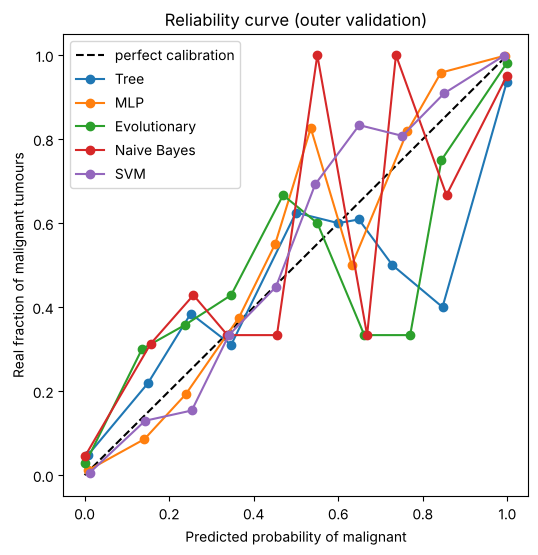

Tree         extreme scores (<0.02 or >0.98): 86%
MLP          extreme scores (<0.02 or >0.98): 80%
Evolutionary extreme scores (<0.02 or >0.98): 95%
Naive Bayes  extreme scores (<0.02 or >0.98): 96%
SVM          extreme scores (<0.02 or >0.98): 73%


In [7]:
fig, ax = plt.subplots(figsize=(6, 6))  # square figure
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")  # ideal diagonal
for key in keys:  # one curve per learner
    sub = scores.filter(pl.col("learner") == key)  # scores of its 25 folds
    frequency, mean_prob = calibration_curve(sub["y"].to_numpy(), sub["score"].to_numpy(), n_bins=10)  # real fraction of malignant tumours per probability bin
    ax.plot(mean_prob, frequency, marker="o", label=names[key])  # the learner's curve
ax.set_xlabel("Predicted probability of malignant")  # horizontal axis
ax.set_ylabel("Real fraction of malignant tumours")  # vertical axis
ax.set_title("Reliability curve (outer validation)")  # title
ax.legend()  # legend
plt.savefig(figures_dir / "02_calibration.png", bbox_inches="tight")  # save
plt.show()  # show
for key in keys:  # how many scores are extreme
    p = scores.filter(pl.col("learner") == key)["score"].to_numpy()  # its scores
    print(f"{names[key]:12s} extreme scores (<0.02 or >0.98): {np.mean((p < 0.02) | (p > 0.98)):.0%}")  # percentage

**What we see:** between 73% (SVM) and 96% (Naive Bayes) of the scores are extreme (< 0.02 or > 0.98), so the curve has only a few points with data and is not very informative. Calibration is better seen in the metrics: with an almost equal AUC (Bayes 0.988 against MLP 0.994), the **log-loss of Naive Bayes is 0.388 against 0.102 for the MLP** and 0.082 for the SVM. Bayes ranks well, but when it is wrong it is wrong with almost total confidence. The tree is the worst (0.582).

### Cell 8: fix the "best" learner BEFORE looking at the test set

## 3) Final test set

**Before looking at it we fix which learner is the "best"**, using the criterion declared in Phase 3: the mean MCC of the outer cross-validation. This way the test result cannot influence that choice.

In [8]:
mean_mcc = {k: fold_mcc[k].mean() for k in keys}  # mean MCC of each learner in the outer CV
best = max(mean_mcc, key=mean_mcc.get)  # the one with the highest mean MCC
print("Mean MCC in the outer CV:", {names[k]: round(float(v), 3) for k, v in mean_mcc.items()})  # all of them
print("Best learner fixed BEFORE the test set:", names[best])  # the chosen one

Mean MCC in the outer CV: {'Tree': 0.841, 'MLP': 0.945, 'Evolutionary': 0.926, 'Naive Bayes': 0.889, 'SVM': 0.943}
Best learner fixed BEFORE the test set: MLP


**What we see:** the MLP is the "best" by 0.002 over the SVM, a difference that is statistically a tie. The rule was fixed beforehand and we respect it.

### Cell 9: final refit on the whole training set and evaluation on the TEST set (only once)

**Final test, only once.** Each learner is refitted on the 455 training rows (same recipe as Phase 5) and scores the 114 test rows. **Nothing is adjusted after seeing these numbers.**

In [9]:
def refit_final(key):  # same recipe as Phase 5, but with the 455 rows
    family, pipeline, grid = learners[key]  # pipeline and grid
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)  # inner validation
    search = GridSearchCV(clone(pipeline), grid, scoring=make_scorer(matthews_corrcoef), cv=inner, n_jobs=-1).fit(X_train, y_train)  # choose hyperparameters
    out_of_fold = cross_val_predict(clone(search.best_estimator_), X_train, y_train, cv=inner, method="predict_proba")[:, 1]  # out-of-sample probabilities
    return search.best_estimator_, best_threshold(y_train, out_of_fold)  # final model and cost threshold

test_prob, final_threshold = {}, {}  # probabilities on the test set and threshold of each learner
for key in keys:  # the five learners
    model, final_threshold[key] = refit_final(key)  # refit (the test set plays no role)
    test_prob[key] = model.predict_proba(X_test)[:, 1]  # the ONLY time the test set is scored
pl.DataFrame({"y": y_test, **test_prob}).write_csv(results_dir / "test_scores.csv")  # save the probabilities
print(f"{'Learner':12s} {'thresh.':>7s} {'MCC':>6s} {'recall':>7s} {'FN':>3s} {'FP':>3s} {'cost':>6s}")  # header
for key in keys:  # results with threshold 0.5 and with the cost threshold
    for threshold_label, t in [("0.5", 0.5), (f"{final_threshold[key]:.2f}", final_threshold[key])]:  # the two thresholds
        m = compute_metrics(y_test, test_prob[key], t)  # metrics on the test set
        print(f"{names[key]:12s} {threshold_label:>7s} {m['mcc']:6.3f} {m['recall']:7.3f} {m['fn']:3d} {m['fp']:3d} {m['cost']:6.3f}")  # one line

Learner      thresh.    MCC  recall  FN  FP   cost
Tree             0.5  0.849   0.857   6   2  0.281
Tree            0.03  0.000   1.000   0  72  0.632
MLP              0.5  0.944   0.929   3   0  0.132
MLP             0.10  0.889   0.952   2   4  0.123
Evolutionary     0.5  0.944   0.929   3   0  0.132
Evolutionary    0.01  0.892   0.976   1   5  0.088
Naive Bayes      0.5  0.887   0.881   5   1  0.228
Naive Bayes     0.01  0.943   0.952   2   1  0.096
SVM              0.5  0.981   0.976   1   0  0.044
SVM             0.38  0.962   0.976   1   1  0.053


**What we see (test set, 114 rows, 42 malignant):**

| Learner | Errors at threshold 0.5 | MCC | With cost threshold |
|---|---|---|---|
| SVM | 1 | 0.981 | cost 0.053 |
| MLP | 3 | 0.944 | cost 0.132 at 0.5 (0.123 with the cost threshold in the reference run; it can change by machine) |
| Evolutionary | 3 | 0.944 | cost 0.088 |
| Naive Bayes | 6 | 0.887 | cost 0.096 (MCC 0.943) |
| Tree | 8 | 0.849 | **breaks** (see below) |

The order matches that of the cross-validation, but the figures are higher because 114 rows give a very noisy estimate. The cost threshold helps Naive Bayes and the evolutionary learner. **It breaks the tree:** its 0.03 threshold classifies everybody as malignant (72 false positives, MCC 0, cost 0.632 = that of the baseline), because with such coarse probabilities the threshold chosen on the training set falls on a jump.

### Cell 10: are the differences significant on the test set? (exact McNemar)

**Exact McNemar:** among the tumours on which the MLP and another learner disagree, does one of them win more often than chance would explain? With 114 tumours there will almost never be significant differences.

In [10]:
correct = {k: (test_prob[k] >= 0.5).astype(int) == y_test for k in keys}  # True if the learner gets each tumour right (threshold 0.5)
for other in keys:  # compare the best with each of the others
    if other == best:  # do not compare it with itself
        continue  # skip
    only_best = int(np.sum(correct[best] & ~correct[other]))  # tumours only the best gets right
    only_other = int(np.sum(~correct[best] & correct[other]))  # tumours only the other gets right
    p = binomtest(min(only_best, only_other), only_best + only_other, 0.5).pvalue if only_best + only_other > 0 else 1.0  # exact McNemar = binomial test on the disagreements
    print(f"{names[best]} vs {names[other]:12s} only the best is right: {only_best} | only the other is right: {only_other} | p = {p:.3f}")  # result

MLP vs Tree         only the best is right: 7 | only the other is right: 2 | p = 0.180
MLP vs Evolutionary only the best is right: 1 | only the other is right: 1 | p = 1.000
MLP vs Naive Bayes  only the best is right: 4 | only the other is right: 1 | p = 0.375
MLP vs SVM          only the best is right: 0 | only the other is right: 2 | p = 0.500


**What we see:** no difference is significant (p ≥ 0.18). The SVM gets 2 tumours right that the MLP gets wrong and the MLP gets none right that the SVM gets wrong, but these are 2 cases: a technical tie.

### Cell 11: uncertainty of the test set (Wilson interval of the recall)

The test set has only 42 malignant tumours, so a single miss moves the recall a lot. The **Wilson interval** measures that uncertainty.

In [11]:
malignant_count = int(y_test.sum())  # malignant tumours in the test set
detected = int(np.sum((test_prob[best] >= 0.5) & (y_test == 1)))  # malignant tumours detected by the best
ci = binomtest(detected, malignant_count).proportion_ci(confidence_level=0.95, method="wilson")  # Wilson interval
print(f"{names[best]}: detects {detected} of {malignant_count} malignant | recall {detected / malignant_count:.3f} | 95% CI [{ci.low:.3f}, {ci.high:.3f}]")  # result

MLP: detects 39 of 42 malignant | recall 0.929 | 95% CI [0.810, 0.975]


**What we see:** the MLP detects 39 of 42 malignant tumours (recall 0.929), with a 95% CI of [0.81, 0.98]: the test set does not allow us to claim much more than "high".

### Cell 12: diagnosis of the best learner (confusion matrix and cost curve)

## 4) Diagnosis of the best learner

Confusion matrix on the test set and cost curve against the threshold (computed with the outer validation, not the test set).

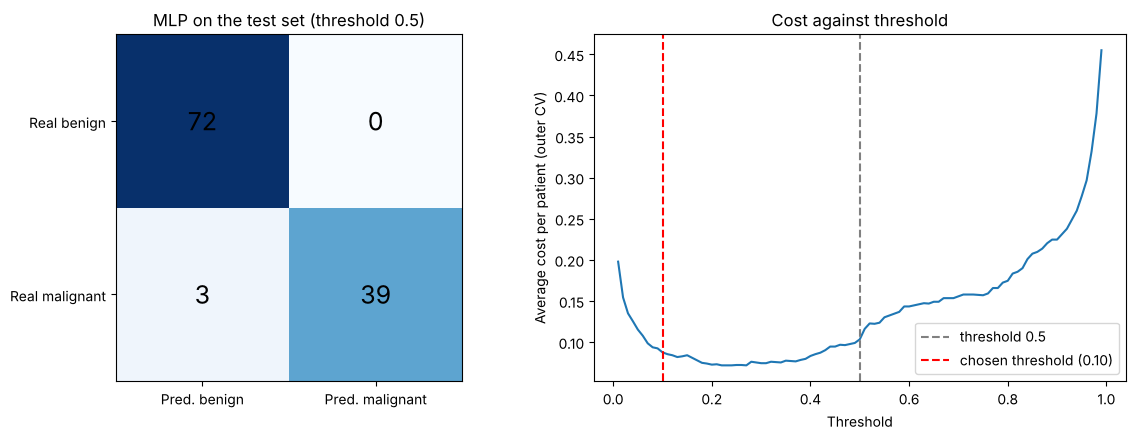

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))  # two plots
matrix = confusion_matrix(y_test, (test_prob[best] >= 0.5).astype(int), labels=[0, 1])  # confusion matrix on the test set
axes[0].imshow(matrix, cmap="Blues")  # draw the matrix
for i in range(2):  # loop over rows
    for j in range(2):  # and columns
        axes[0].text(j, i, matrix[i, j], ha="center", va="center", fontsize=18)  # number in each cell
axes[0].set_xticks([0, 1])  # horizontal ticks
axes[0].set_xticklabels(["Pred. benign", "Pred. malignant"])  # names
axes[0].set_yticks([0, 1])  # vertical ticks
axes[0].set_yticklabels(["Real benign", "Real malignant"])  # names
axes[0].set_title(f"{names[best]} on the test set (threshold 0.5)")  # title
sub = scores.filter(pl.col("learner") == best)  # scores of the best in the outer CV
thresholds = np.linspace(0.01, 0.99, 99)  # thresholds to try
costs = [compute_metrics(sub["y"].to_numpy(), sub["score"].to_numpy(), t)["cost"] for t in thresholds]  # cost of each threshold in the outer CV
axes[1].plot(thresholds, costs)  # cost curve
axes[1].axvline(0.5, color="gray", linestyle="--", label="threshold 0.5")  # default threshold
axes[1].axvline(final_threshold[best], color="red", linestyle="--", label=f"chosen threshold ({final_threshold[best]:.2f})")  # cost threshold
axes[1].set_xlabel("Threshold")  # horizontal axis
axes[1].set_ylabel("Average cost per patient (outer CV)")  # vertical axis
axes[1].set_title("Cost against threshold")  # title
axes[1].legend()  # legend
plt.tight_layout()  # adjust spacing
plt.savefig(figures_dir / "03_best_learner_diagnosis.png", bbox_inches="tight")  # save
plt.show()  # show

**What we see:** at threshold 0.5 the MLP makes 3 false negatives and 0 false positives. The cost curve is very flat between ~0.1 and 0.5; the threshold chosen on the whole training set (0.10 in the reference run; it varies a little with the machine) sits at the left edge of the valley, a bit low, and for this learner the gain is zero or small.

### Cell 13: error analysis on the test set

## 5) Error analysis

Which test tumours do the models fail on, and do they match what we saw in Phase 2?

Tumours that everybody gets right: 103 of 114
Tumours that at least one learner gets wrong: 11
Tumours that all five learners get wrong: 1
  Tree         fails on 8 tumours
  MLP          fails on 3 tumours
  Evolutionary fails on 3 tumours
  Naive Bayes  fails on 6 tumours
  SVM          fails on 1 tumours


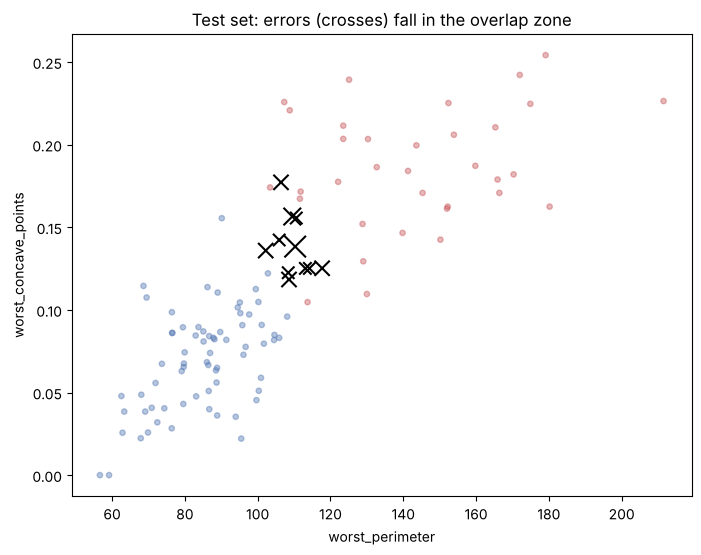

worst_perimeter of the difficult ones: from 102 to 118
worst_concave_points of the difficult ones: from 0.12 to 0.18


In [13]:
failures = np.sum([~correct[k] for k in keys], axis=0)  # how many learners fail on each test tumour
print("Tumours that everybody gets right:", int(np.sum(failures == 0)), "of", len(y_test))  # the majority
print("Tumours that at least one learner gets wrong:", int(np.sum(failures > 0)))  # the difficult ones
print("Tumours that all five learners get wrong:", int(np.sum(failures == 5)))  # the impossible ones
for k in keys:  # errors per learner
    print(f"  {names[k]:12s} fails on {int((~correct[k]).sum())} tumours")  # how many
i_per, i_con = columns.index("worst_perimeter"), columns.index("worst_concave_points")  # positions of the two best features
fig, ax = plt.subplots(figsize=(8, 6))  # figure
easy = failures == 0  # tumours without errors
ax.scatter(X_test[easy, i_per], X_test[easy, i_con], c=np.where(y_test[easy] == 1, "#C44E52", "#4C72B0"), s=15, alpha=0.4)  # background: red malignant, blue benign
ax.scatter(X_test[~easy, i_per], X_test[~easy, i_con], c="black", s=40 + 40 * failures[~easy], marker="x")  # crosses: the more learners fail, the bigger
ax.set_xlabel("worst_perimeter")  # horizontal axis
ax.set_ylabel("worst_concave_points")  # vertical axis
ax.set_title("Test set: errors (crosses) fall in the overlap zone")  # title
plt.savefig(figures_dir / "04_errors.png", bbox_inches="tight")  # save
plt.show()  # show
difficult = np.where(~easy)[0]  # positions of the difficult tumours
print(f"worst_perimeter of the difficult ones: from {X_test[difficult, i_per].min():.0f} to {X_test[difficult, i_per].max():.0f}")  # range
print(f"worst_concave_points of the difficult ones: from {X_test[difficult, i_con].min():.2f} to {X_test[difficult, i_con].max():.2f}")  # range

**What we see:** 103 of 114 tumours are got right by everybody. The 11 that at least one learner gets wrong lie **in a narrow band** (`worst_perimeter` between 102 and 118; `worst_concave_points` between 0.12 and 0.18): the overlap zone already visible in Phase 2. **One malignant tumour is missed by all five learners**: with these 30 measurements it looks benign. It is a **limit of the data, not of the model**.

### Cell 14: evolutionary hypothesis, does it tie with a gradient-based linear model?

## 6) The evolutionary hypothesis

We hypothesized that evolutionary search would match a gradient-based method but at a much higher cost. We check it with a logistic regression (without hyperparameter tuning, only as a reference).

In [14]:
logistic = build(True, LogisticRegression(max_iter=1000))  # logistic regression with scaling (no hyperparameter tuning)
logistic_mcc, logistic_times = [], []  # MCC and time of each fold
for train_idx, val_idx in folds:  # the same 25 folds
    start = time.perf_counter()  # clock
    model = clone(logistic).fit(X_train[train_idx], y_train[train_idx])  # train on the fold
    logistic_times.append(time.perf_counter() - start)  # fit time
    logistic_mcc.append(compute_metrics(y_train[val_idx], model.predict_proba(X_train[val_idx])[:, 1])["mcc"])  # MCC on validation
diff, t, p = corrected_ttest(fold_mcc["evolutionary"], np.array(logistic_mcc), n_train, n_val)  # evolutionary - logistic
print(f"Evolutionary MCC {fold_mcc['evolutionary'].mean():.3f} | logistic MCC {np.mean(logistic_mcc):.3f} | difference {diff:+.3f} | corrected p = {p:.2f}")  # comparison
start = time.perf_counter()  # evolutionary clock
build(True, EvolutionaryClassifier()).fit(X_train[folds[0][0]], y_train[folds[0][0]])  # one evolutionary fit (40 individuals x 100 generations)
evo_time = time.perf_counter() - start  # its time
print(f"Time of one fit: evolutionary {evo_time:.2f} s | logistic {np.mean(logistic_times) * 1000:.0f} ms | the evolutionary learner is {evo_time / np.mean(logistic_times):.0f} times slower")  # cost of blind search

Evolutionary MCC 0.926 | logistic MCC 0.946 | difference -0.020 | corrected p = 0.30
Time of one fit: evolutionary 0.09 s | logistic 4 ms | the evolutionary learner is 21 times slower


**What we see:** the evolutionary learner (MCC 0.926) and the logistic regression (0.946) are not distinguishable (corrected p = 0.30), but an evolutionary fit is about 20 to 35 times slower depending on the run and the machine (a fraction of a second against a few milliseconds). **It is not confirmed that it performs worse; the cost of blind search is confirmed.** The part of the hypothesis about optimizing an asymmetric cost inside the evolution was not tested: the fitness was the MCC.

## 7) Answer to the Phase 1 hypotheses

| Claim of the hypothesis | Verdict | Evidence |
|---|---|---|
| Success depends on handling redundancy and the threshold, not on complex boundaries | **Partially confirmed** | A linear evolved model ties with the logistic regression (p = 0.30) and with MLP and SVM (Holm p ≥ 0.94); the cost threshold lowers the cost by 4% to 31%. But the leading group includes an SVM with a non-linear kernel |
| The connectionist learner will dominate | **Rejected as domination, confirmed as part of the leading group** | MLP first in MCC (0.945) but ties with SVM (Holm p = 0.95) and evolutionary; only the tree is significantly worse |
| Bayes: overconfident probabilities and worst threshold | **Half confirmed** | Calibration confirmed: log-loss 0.388 against 0.102 with almost equal AUC and 96% extreme scores. Threshold not confirmed: its cost falls by 25% when chosen by cost |
| Tree: transparent but worse calibrated | **Confirmed, more strongly than expected** | Worst MCC (0.841), worst log-loss (0.582) and a degenerate cost threshold on the test set |
| Analogizer threatened by correlations | **Rejected** | The SVM ties with the MLP, has the lowest cost in the CV (0.072) and the best result on the test set (1 error); standardization and the kernel absorb the redundancy |
| Evolutionary: matches in quality, blind search is expensive | **Confirmed in cost, not in quality** | Ties with the logistic regression (p = 0.30), 20 to 35 times slower; in Phase 4 the seeds stall at different levels |

## Limits

- **Small sample:** 569 rows and a test set of 114 with only 42 malignant tumours; one error moves the recall by 2.4 points. The cross-validation figures (25 folds) are more reliable than those of the test set.
- **Ceiling effect:** MLP, SVM, evolutionary and Naive Bayes are not distinguishable. **Nothing authorizes saying that one "wins".**
- **The 5:1 cost is an assumption**, not clinical data.
- **The threshold is chosen with training scores:** it works with graded probabilities and breaks with very coarse ones (the tree).
- **Grids widened three times** (declared in Phase 5); some hyperparameters touch the edges.
- **Stack:** `MLPClassifier` was used instead of Keras/JAX.
- **A single data source:** we cannot claim it works in other hospitals; this is **not a diagnosis**.

## Next steps

- Try another cost ratio (for example 10:1) and see whether the ranking changes.
- Optimise the asymmetric cost inside the evolution (not tested).
- Calibrate the tree and Naive Bayes (Platt or isotonic).
- Repeat with another clinical dataset to see whether the technical tie holds.

**Next:** Phase 7 · Delivery README.